# Diabetes Health Indicators

First experiment using the shared workflow in `ml_workflow.py`.
The target is the binary indicator `Diabetes_binary`.

We use `diabetes_binary_health_indicators_BRFSS2015.csv`,
which retains the imbalanced class distribution.


In [1]:
import pandas as pd

from ml_workflow import (
    evaluate_classifier,
    load_diabetes,
    split_dataset,
    train_logistic_baseline,
)


## Dataset

We check the number of samples, the number of features, missing values,
and the class distribution.


In [2]:
X, y = load_diabetes()

print(f"Samples: {X.shape[0]}")
print(f"Features: {X.shape[1]}")
print(f"Missing feature values: {X.isna().sum().sum()}")


Samples: 253680
Features: 21
Missing feature values: 0


In [3]:
class_distribution = pd.DataFrame({
    "count": y.value_counts().sort_index(),
    "proportion": y.value_counts(normalize=True).sort_index(),
})
class_distribution.index.name = "Diabetes_binary"
class_distribution.round(3)


,count,proportion
Diabetes_binary,,
0,218334,0.861
1,35346,0.139


## Train/test split

We use 80% of the data for training and 20% for testing.
The split is stratified to preserve similar class proportions.
The random seed is fixed at 67.


In [4]:
X_train, X_test, y_train, y_test = split_dataset(
    X, y, test_size=0.2, random_state=67
)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")


Training samples: 202944
Test samples: 50736


## Logistic regression

The pipeline applies median imputation and standardization before
logistic regression. The preprocessing steps are fitted on the training split.


In [5]:
model = train_logistic_baseline(X_train, y_train)


## Test results

Precision, recall, and F1-score refer to the positive class (`1`).
We also calculate the test accuracy of always predicting the majority
class identified in the training split.


In [6]:
scores = evaluate_classifier(model, X_test, y_test)

majority_class = y_train.mode().iloc[0]
majority_accuracy = y_test.eq(majority_class).mean()
print(f"Majority-class accuracy: {majority_accuracy:.3f}")

results = pd.Series(scores, name="Logistic regression").to_frame()
results.round(3)


Majority-class accuracy: 0.861


,Logistic regression
accuracy,0.862
balanced_accuracy,0.565
precision,0.522
recall,0.153
f1,0.237
roc_auc,0.818
average_precision,0.394


The positive class represents 13.9% of the dataset. Always predicting the training majority class gives 86.1% accuracy on the test split. Logistic regression reaches 86.2% accuracy, with 56.5% balanced accuracy and 15.3% recall for the positive class.

The low recall shows that this first model misses most positive examples at its default decision threshold. Further experiments will compare class weighting and other classifiers using cross-validation on the training split.


## Cross-validation

We evaluate the pipeline using five stratified folds of the training split.
The table reports the mean and standard deviation of each metric.

In [7]:
from ml_workflow import cross_validate_classifier

cv_scores = cross_validate_classifier(model, X_train, y_train)
cv_scores.agg(["mean", "std"]).T.round(3)

,mean,std
accuracy,0.864,0.001
balanced_accuracy,0.569,0.002
precision,0.536,0.008
recall,0.159,0.005
f1,0.246,0.006
roc_auc,0.823,0.002
average_precision,0.407,0.002


## Class weighting

In [8]:
balanced_model = train_logistic_baseline(
    X_train, y_train, class_weight="balanced"
)

balanced_cv_scores = cross_validate_classifier(
    balanced_model, X_train, y_train, random_state=67
)

comparison = pd.DataFrame({
    "standard": cv_scores.mean(),
    "balanced": balanced_cv_scores.mean(),
}).T

comparison.round(3)

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
standard,0.864,0.569,0.536,0.159,0.246,0.823,0.407
balanced,0.733,0.747,0.313,0.766,0.444,0.824,0.406


Class weighting increases recall from 0.159 to 0.766, while precision decreases from 0.536 to 0.313. Balanced accuracy improves from 0.569 to 0.747, and F1 increases from 0.246 to 0.444. The weighted model detects more positive cases but produces more false positives, reducing overall accuracy from 0.864 to 0.733. We retain this configuration for comparison with other classifiers.

## Comparing classifiers

In [9]:
from ml_workflow import build_models, compare_models

SEED = 67

models = build_models(random_state=SEED)

comparison, fold_scores = compare_models(
    models,
    X_train,
    y_train,
    random_state=SEED,
)

mean_scores = comparison.xs("mean", axis=1, level=1)
mean_scores.sort_values("f1", ascending=False).round(3)

Cross-validating Logistic regression
Cross-validating Logistic regression (balanced)
Cross-validating Gaussian Naive Bayes
Cross-validating Linear SVM (balanced)
Cross-validating MLP


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
model,,,,,,,
Logistic regression (balanced),0.733,0.747,0.313,0.766,0.444,0.824,0.406
Linear SVM (balanced),0.728,0.747,0.310,0.772,0.442,0.823,0.407
Gaussian Naive Bayes,0.774,0.688,0.324,0.569,0.413,0.785,0.342
MLP,0.866,0.573,0.563,0.166,0.256,0.828,0.427
Logistic regression,0.864,0.569,0.536,0.160,0.246,0.823,0.407


Balanced logistic regression and the balanced linear SVM achieve the highest mean F1-scores, at 0.444 and 0.442. The MLP has the highest ROC AUC (0.828) and average precision (0.427), while its recall is 0.166 at the current decision threshold. The ranking therefore depends on the evaluation metric. We retain the two balanced linear models for the next experiment, using F1 as our main selection criterion.

## Feature selection

In [10]:
from ml_workflow import search_feature_selection

candidate_names = [
    "Logistic regression (balanced)",
    "Linear SVM (balanced)",
]
candidates = {name: models[name] for name in candidate_names}

feature_results, feature_searches = search_feature_selection(
    candidates,
    X_train,
    y_train,
    random_state=SEED,
)

feature_results.round(3)

Searching feature selection and C for Logistic regression (balanced)
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Searching feature selection and C for Linear SVM (balanced)
Fitting 5 folds for each of 12 candidates, totalling 60 fits


,model,percentile,C,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,f1_std
0,Logistic regression (balanced),100,1.0,0.733,0.747,0.313,0.766,0.444,0.824,0.406,0.002
1,Logistic regression (balanced),100,10.0,0.733,0.747,0.313,0.766,0.444,0.824,0.406,0.002
2,Logistic regression (balanced),100,0.1,0.733,0.747,0.313,0.766,0.444,0.824,0.406,0.002
3,Logistic regression (balanced),75,0.1,0.732,0.745,0.311,0.765,0.443,0.821,0.401,0.002
4,Logistic regression (balanced),75,1.0,0.732,0.745,0.311,0.765,0.443,0.821,0.401,0.002
5,Logistic regression (balanced),75,10.0,0.732,0.745,0.311,0.765,0.443,0.821,0.401,0.002
6,Linear SVM (balanced),100,10.0,0.728,0.747,0.310,0.772,0.442,0.823,0.407,0.003
7,Linear SVM (balanced),100,1.0,0.728,0.747,0.310,0.772,0.442,0.823,0.407,0.003
8,Linear SVM (balanced),100,0.1,0.728,0.747,0.310,0.772,0.442,0.823,0.407,0.003
9,Logistic regression (balanced),50,1.0,0.730,0.744,0.310,0.762,0.441,0.819,0.399,0.002


### Best configuration for each classifier

We report the configuration with the highest mean cross-validation F1-score for each classifier.

In [11]:
feature_results.groupby("model", sort=False).head(1).round(3)

,model,percentile,C,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,f1_std
0,Logistic regression (balanced),100,1.0,0.733,0.747,0.313,0.766,0.444,0.824,0.406,0.002
6,Linear SVM (balanced),100,10.0,0.728,0.747,0.310,0.772,0.442,0.823,0.407,0.003


### Selected features

We display the best parameters and the feature names retained by each pipeline after refitting it on the full training split.

In [12]:
for name, search in feature_searches.items():
    features = search.best_estimator_[:-1].get_feature_names_out()
    print(name, search.best_params_)
    print(f"{len(features)} selected features:", features.tolist()) 

Logistic regression (balanced) {'classifier__C': 1.0, 'select__percentile': 100}
21 selected features: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
Linear SVM (balanced) {'classifier__C': 10.0, 'select__percentile': 100}
21 selected features: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


Both classifiers achieve their highest mean CV F1 using all 21 features. Balanced logistic regression with C=1 obtains F1=0.444, compared with 0.442 for the balanced linear SVM with C=10. Retaining 75% of the features gives a slightly lower F1-score of approximately 0.443 for logistic regression. Following our highest-mean-F1 criterion, we retain all features.

## Final test evaluation

We select the configuration with the highest mean CV F1-score from the feature-selection search and report its test performance. Its complete pipeline has already been refitted on the full training split.

In [13]:
best_row = feature_results.iloc[0]
best_name = best_row["model"]
final_search = feature_searches[best_name]
final_model = final_search.best_estimator_

print("Selected model:", best_name)
print("Parameters:", final_search.best_params_)

test_scores = evaluate_classifier(final_model, X_test, y_test)
cv_metrics = best_row[list(test_scores)].astype(float)

final_results = pd.DataFrame({
    "CV mean": cv_metrics,
    "Test": pd.Series(test_scores),
})
final_results.round(3)

Selected model: Logistic regression (balanced)
Parameters: {'classifier__C': 1.0, 'select__percentile': 100}


,CV mean,Test
accuracy,0.733,0.727
balanced_accuracy,0.747,0.741
precision,0.313,0.306
recall,0.766,0.761
f1,0.444,0.437
roc_auc,0.824,0.818
average_precision,0.406,0.393


### Test-set figures

The confusion matrix shows classification errors at the model’s default decision threshold. ROC and precision–recall curves describe performance across thresholds. The dashed lines show chance references.

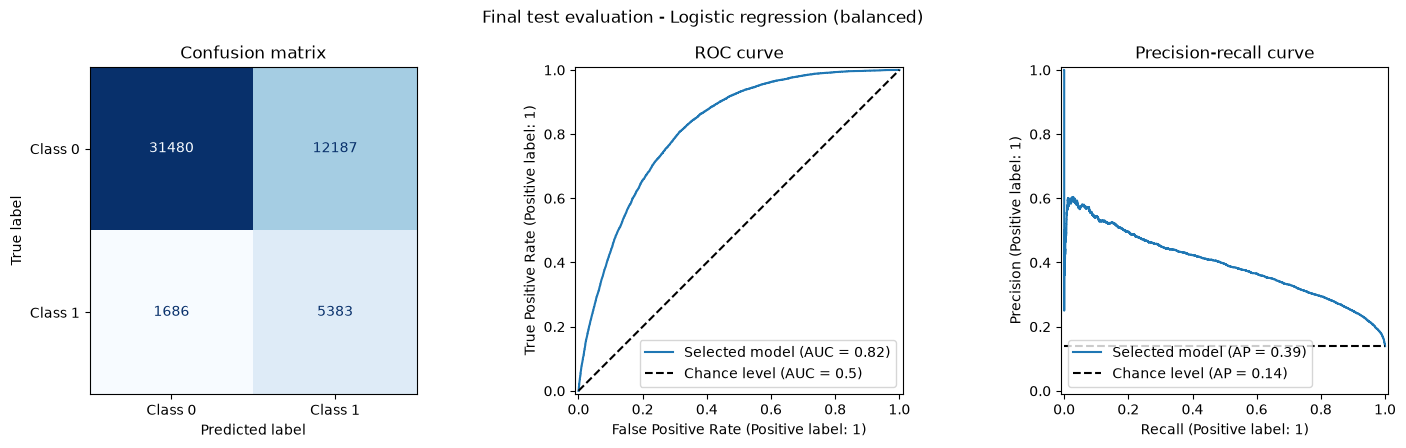

In [14]:
import matplotlib.pyplot as plt
from ml_workflow import plot_test_results

fig = plot_test_results(
    final_model,
    X_test,
    y_test,
    title=f"Final test evaluation - {best_name}",
)
plt.show()

### Final results and conclusion

The selected balanced logistic regression uses C=1 and all 21 features. Its test F1-score is 0.437, compared with 0.444 during cross-validation. Recall reaches 0.761, while precision is 0.306, showing that detecting more positive cases comes with many false positives.

The confusion matrix contains 5,383 true positives, 1,686 false negatives and 12,187 false positives. ROC AUC is 0.818 and average precision is 0.393, above the prevalence reference of approximately 0.14 shown on the precision–recall curve. The relatively close CV and test scores suggest consistent performance across these splits. The main limitation of this configuration is its low precision at the default decision threshold.